# Advanced Statistical Analysis & Hypothesis Testing
### Restaurant Tipping Behaviour: Parametric and Non-Parametric Inference with ANOVA

**Objective.** Perform rigorous inferential statistics on a real business dataset (restaurant bills and tips) by:

1. Testing normality (Shapiro-Wilk and Kolmogorov-Smirnov)
2. Comparing two groups (Welch t-test and Mann-Whitney U)
3. Comparing many groups (One-Way and Two-Way ANOVA, with Tukey HSD post-hoc analysis)
4. Documenting hypotheses, confidence intervals, effect sizes and conclusions

**Significance level:** α = 0.05 throughout.

**Dataset:** the classic `tips` dataset (244 restaurant bills, collected by a waiter in the USA). Columns used: `total_bill`, `tip`, `smoker`, `day`, `time`, `size`.

## 1. Setup and Data Loading

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import lilliefors

sns.set_theme(style='whitegrid', context='notebook', palette='Set2')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
ALPHA = 0.05
RESULTS = []   # collects every test for the final summary table

df = sns.load_dataset('tips')[['total_bill', 'tip', 'smoker', 'day', 'time', 'size']]
df['tip_pct'] = df['tip'] / df['total_bill'] * 100   # tip as % of bill (business KPI)
print(df.shape, '| missing values:', int(df.isna().sum().sum()))
df.head()

(244, 7) | missing values: 0


,total_bill,tip,smoker,day,time,size,tip_pct
0,16.99,1.01,No,Sun,Dinner,2,5.944673
1,10.34,1.66,No,Sun,Dinner,3,16.054159
2,21.01,3.50,No,Sun,Dinner,3,16.658734
3,23.68,3.31,No,Sun,Dinner,2,13.978041
4,24.59,3.61,No,Sun,Dinner,4,14.680765


In [2]:
display(df.describe().round(2))
display(df.groupby('day', observed=True)[['total_bill','tip_pct']].agg(['count','mean','std']).round(2))

,total_bill,tip,size,tip_pct
count,244.00,244.00,244.00,244.00
mean,19.79,3.00,2.57,16.08
std,8.90,1.38,0.95,6.11
min,3.07,1.00,1.00,3.56
25%,13.35,2.00,2.00,12.91
50%,17.80,2.90,2.00,15.48
75%,24.13,3.56,3.00,19.15
max,50.81,10.00,6.00,71.03


total_bill              tip_pct             
          count   mean   std   count   mean   std
day                                              
Thur         62  17.68  7.89      62  16.13  3.87
Fri          19  17.15  8.30      19  16.99  4.77
Sat          87  20.44  9.48      87  15.32  5.13
Sun          76  21.41  8.83      76  16.69  8.47

**Variables analysed**

| Variable | Role | Type |
|---|---|---|
| `total_bill` | Primary outcome (bill size, USD) | Continuous |
| `tip_pct` | Secondary outcome (tip as % of bill) | Continuous |
| `smoker`, `time` | Two-level factors (smoker Yes/No, Lunch/Dinner) | Categorical |
| `day` (Thu, Fri, Sat, Sun) | Four-level factor | Categorical |

## 2. Normality Testing

Parametric tests assume approximately normal data (or residuals). We test this with two complementary tests:

- **Shapiro-Wilk**: powerful omnibus test of normality, best for small to medium samples.
- **Kolmogorov-Smirnov (KS)**: compares the empirical CDF with a normal CDF. Because the mean and SD are *estimated* from the sample, the standard KS p-value is too conservative, so we also report the **Lilliefors-corrected** version.

**Hypotheses (for each sample):**
- H₀: the sample comes from a normal distribution
- H₁: the sample does not come from a normal distribution

A p-value below 0.05 means we reject normality.

In [3]:
def normality_table(data, value, by):
    rows = []
    for g, s in data.groupby(by, observed=True)[value]:
        sw_stat, sw_p = stats.shapiro(s)
        ks_stat, ks_p = stats.kstest(s.values, stats.norm(s.mean(), s.std(ddof=1)).cdf)
        lf_stat, lf_p = lilliefors(s, dist='norm')
        rows.append({'group': g, 'n': len(s), 'skew': stats.skew(s), 'SW W': sw_stat, 'SW p': sw_p,
                     'KS D': ks_stat, 'KS p': ks_p, 'Lilliefors p': lf_p,
                     'Normal? (SW)': 'Yes' if sw_p >= ALPHA else 'No'})
    return pd.DataFrame(rows).set_index('group').round(4)

print('=== total_bill by smoker ===');    display(normality_table(df, 'total_bill', 'smoker'))
print('=== tip_pct by smoker ===');    display(normality_table(df, 'tip_pct', 'smoker'))
print('=== total_bill by day ===');    display(normality_table(df, 'total_bill', 'day'))
print('=== Overall total_bill ===');   display(normality_table(df.assign(all='All'), 'total_bill', 'all'))

=== total_bill by smoker ===


,n,skew,SW W,SW p,KS D,KS p,Lilliefors p,Normal? (SW)
group,,,,,,,,
Yes,93,0.8831,0.9367,0.0002,0.1287,0.0840,0.001,No
No,151,1.2872,0.9045,0.0000,0.1157,0.0322,0.001,No


=== tip_pct by smoker ===


,n,skew,SW W,SW p,KS D,KS p,Lilliefors p,Normal? (SW)
group,,,,,,,,
Yes,93,3.1570,0.7626,0.0000,0.1612,0.0140,0.0010,No
No,151,0.2087,0.9893,0.3062,0.0624,0.5763,0.2162,Yes


=== total_bill by day ===


,n,skew,SW W,SW p,KS D,KS p,Lilliefors p,Normal? (SW)
group,,,,,,,,
Thur,62,1.3276,0.8845,0.0000,0.1394,0.1635,0.0071,No
Fri,19,1.2104,0.8958,0.0409,0.2241,0.2550,0.0138,No
Sat,87,1.2402,0.9035,0.0000,0.1465,0.0429,0.0010,No
Sun,76,0.8068,0.9479,0.0036,0.1189,0.2148,0.0172,No


=== Overall total_bill ===


,n,skew,SW W,SW p,KS D,KS p,Lilliefors p,Normal? (SW)
group,,,,,,,,
All,244,1.1262,0.9197,0.0,0.1188,0.0019,0.001,No


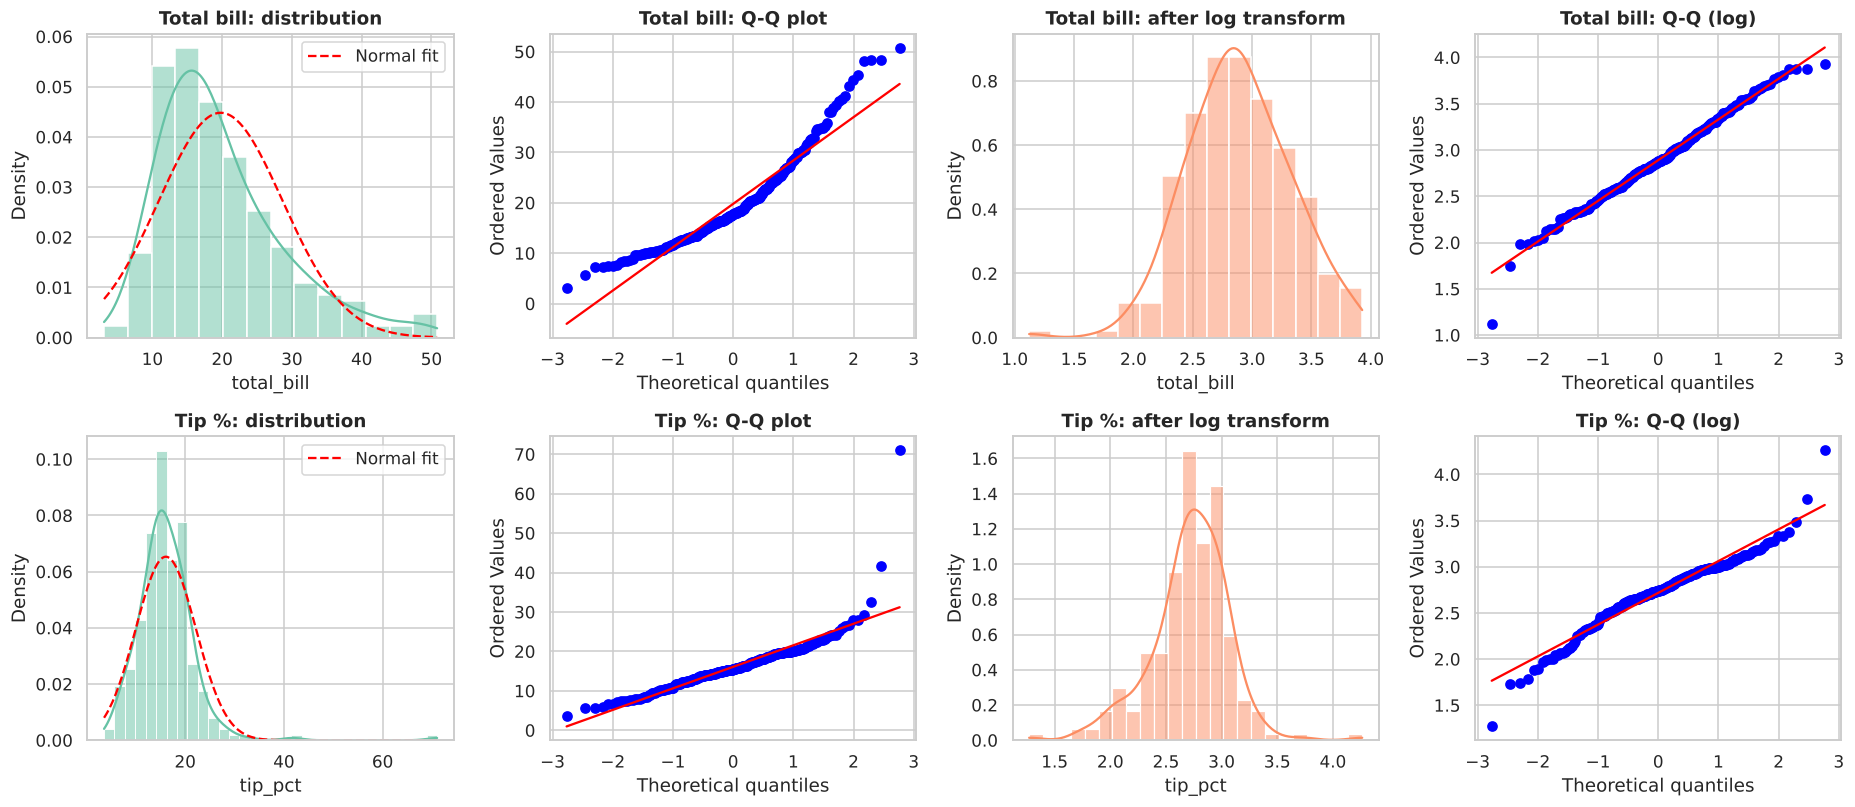

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for j, (col, title) in enumerate([('total_bill', 'Total bill'), ('tip_pct', 'Tip %')]):
    s = df[col]
    sns.histplot(s, kde=True, stat='density', ax=axes[j, 0], color='#66c2a5')
    x = np.linspace(s.min(), s.max(), 200)
    axes[j, 0].plot(x, stats.norm.pdf(x, s.mean(), s.std()), 'r--', label='Normal fit'); axes[j, 0].legend()
    axes[j, 0].set_title(f'{title}: distribution')
    stats.probplot(s, dist='norm', plot=axes[j, 1]); axes[j, 1].set_title(f'{title}: Q-Q plot')
    sns.histplot(np.log(s), kde=True, stat='density', ax=axes[j, 2], color='#fc8d62')
    axes[j, 2].set_title(f'{title}: after log transform')
    stats.probplot(np.log(s), dist='norm', plot=axes[j, 3]); axes[j, 3].set_title(f'{title}: Q-Q (log)')
plt.tight_layout(); plt.show()

In [5]:
# Does a log transform repair the normality of the bill? (used later as a robustness check)
lg = np.log(df['total_bill'])
print('Shapiro-Wilk  raw total_bill : W=%.4f, p=%.2e' % stats.shapiro(df['total_bill']))
print('Shapiro-Wilk  log total_bill : W=%.4f, p=%.4f' % stats.shapiro(lg))

Shapiro-Wilk  raw total_bill : W=0.9197, p=3.32e-10
Shapiro-Wilk  log total_bill : W=0.9913, p=0.1576


## 3. Two-Sample Tests: Parametric vs Non-Parametric

For each comparison we run:

- **Welch's t-test**: compares means without assuming equal variances (the safer default).
- **Mann-Whitney U**: compares the distributions via ranks, with no normality assumption.

We also report **Levene's test** (equal variances), the **95% confidence interval** for the mean difference, and effect sizes (**Cohen's d** and the **rank-biserial correlation**).

In [6]:
def two_sample(data, value, factor, a, b, label):
    x = data.loc[data[factor] == a, value]; y = data.loc[data[factor] == b, value]
    lev_p = stats.levene(x, y).pvalue
    t = stats.ttest_ind(x, y, equal_var=False)
    ci = t.confidence_interval(0.95)                      # CI for mean(x) - mean(y)
    u = stats.mannwhitneyu(x, y, alternative='two-sided')
    sp = np.sqrt(((len(x)-1)*x.var(ddof=1) + (len(y)-1)*y.var(ddof=1)) / (len(x)+len(y)-2))
    d = (x.mean() - y.mean()) / sp
    rbc = 2*u.statistic/(len(x)*len(y)) - 1               # rank-biserial correlation
    out = pd.Series({
        f'mean {a}': x.mean(), f'mean {b}': y.mean(), 'mean diff': x.mean()-y.mean(),
        '95% CI low': ci.low, '95% CI high': ci.high, 'Levene p': lev_p,
        'Welch t': t.statistic, 'Welch df': t.df, 'Welch p': t.pvalue,
        'Mann-Whitney U': u.statistic, 'MWU p': u.pvalue, "Cohen's d": d, 'rank-biserial r': rbc})
    RESULTS.append({'Test': f'Welch t-test: {label}', 'Statistic': t.statistic, 'p-value': t.pvalue,
                    'Decision': 'Reject H0' if t.pvalue < ALPHA else 'Fail to reject H0'})
    RESULTS.append({'Test': f'Mann-Whitney U: {label}', 'Statistic': u.statistic, 'p-value': u.pvalue,
                    'Decision': 'Reject H0' if u.pvalue < ALPHA else 'Fail to reject H0'})
    return out.round(4)

def plot_two(data, value, factor, title, ylabel):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    sns.boxplot(data=data, x=factor, y=value, ax=ax[0], width=.5); sns.stripplot(data=data, x=factor, y=value, ax=ax[0], color='k', alpha=.25, size=3)
    ax[0].set_title(title); ax[0].set_ylabel(ylabel)
    sns.violinplot(data=data, x=factor, y=value, ax=ax[1], inner='quartile'); ax[1].set_title('Distribution shape')
    sns.pointplot(data=data, x=factor, y=value, errorbar=('ci', 95), ax=ax[2], capsize=.12); ax[2].set_title('Group means with 95% CI')
    plt.tight_layout(); plt.show()

### 3.1 Test A: Is the average bill different for smoking and non-smoking parties?

- **H₀:** μ_Smoker = μ_Non-smoker (equal mean bill)
- **H₁:** μ_Smoker ≠ μ_Non-smoker
- For Mann-Whitney U: H₀: the two bill distributions are identical (neither group tends to have larger values); H₁: they differ.

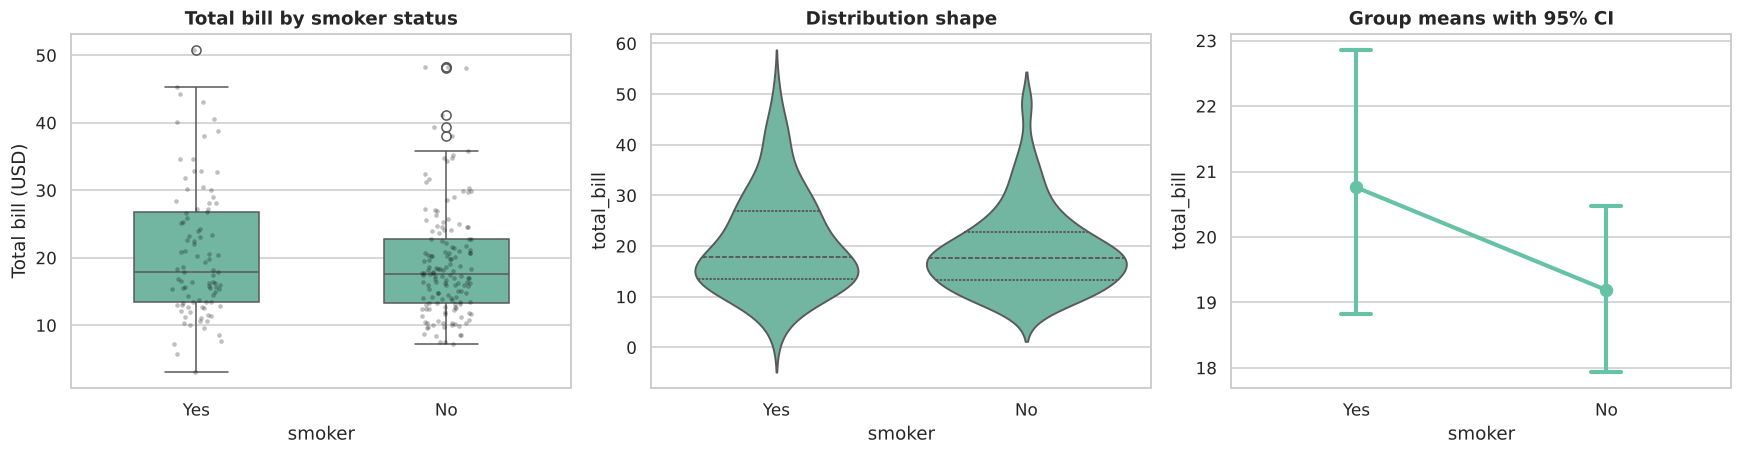

,value
mean Yes,20.7563
mean No,19.1883
mean diff,1.5681
95% CI low,-0.8422
95% CI high,3.9784
Levene p,0.0452
Welch t,1.2843
Welch df,169.6259
Welch p,0.2008
Mann-Whitney U,7531.5000


In [7]:
plot_two(df, 'total_bill', 'smoker', 'Total bill by smoker status', 'Total bill (USD)')
display(two_sample(df, 'total_bill', 'smoker', 'Yes', 'No', 'total_bill, Smoker vs Non-smoker').to_frame('value'))

### 3.2 Test B: Do smokers and non-smokers tip a different percentage?

- **H₀:** μ_Smoker = μ_Non-smoker (equal mean tip percentage)
- **H₁:** μ_Smoker ≠ μ_Non-smoker

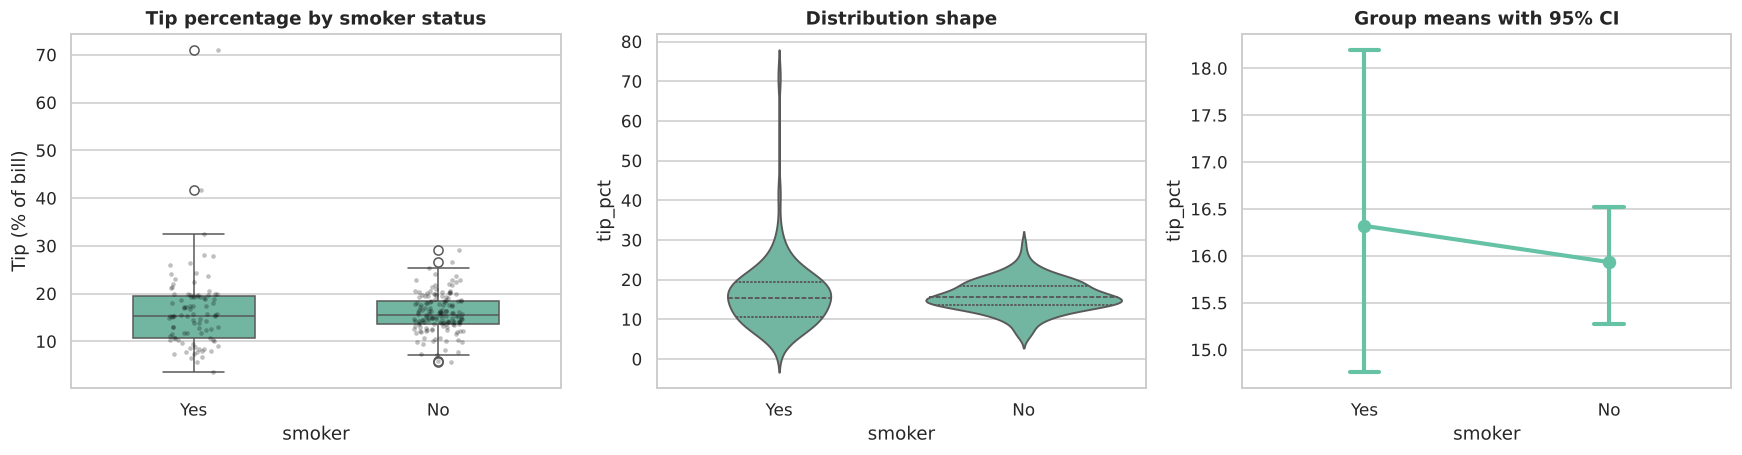

,value
mean Yes,16.3196
mean No,15.9328
mean diff,0.3868
95% CI low,-1.4758
95% CI high,2.2493
Levene p,0.0002
Welch t,0.4112
Welch df,117.2810
Welch p,0.6817
Mann-Whitney U,6709.5000


In [8]:
plot_two(df, 'tip_pct', 'smoker', 'Tip percentage by smoker status', 'Tip (% of bill)')
display(two_sample(df, 'tip_pct', 'smoker', 'Yes', 'No', 'tip_pct, Smoker vs Non-smoker').to_frame('value'))

### 3.3 Test C: Do lunch and dinner bills differ?

- **H₀:** μ_Dinner = μ_Lunch
- **H₁:** μ_Dinner ≠ μ_Lunch

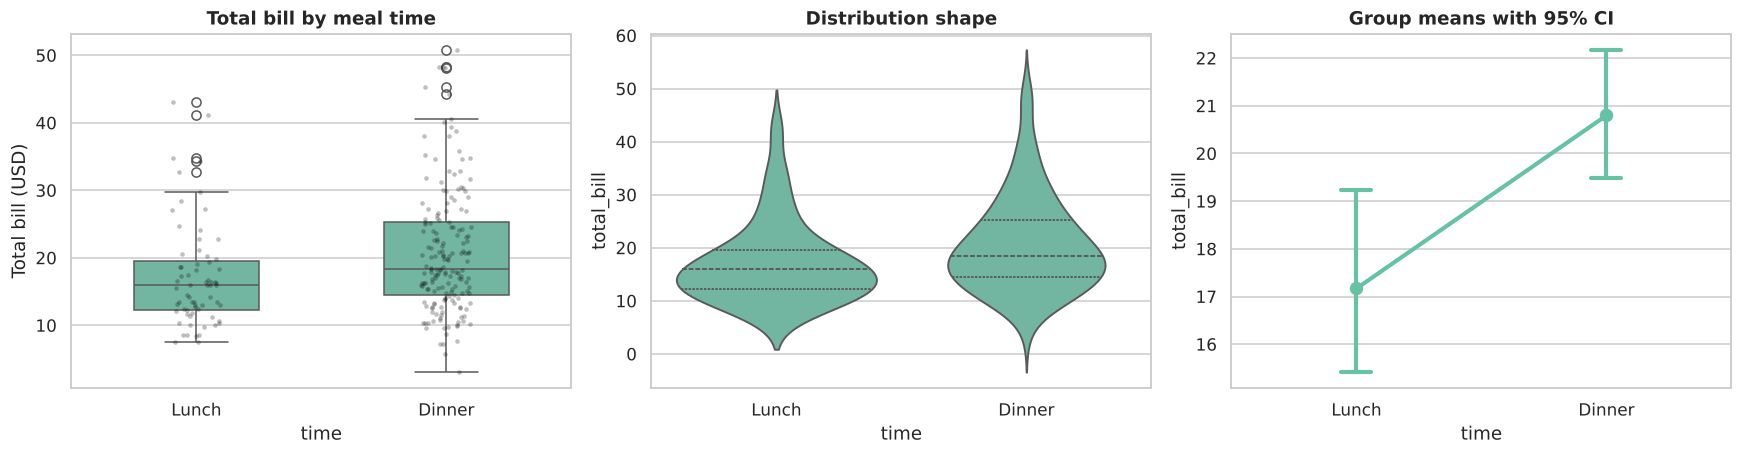

,value
mean Dinner,20.7972
mean Lunch,17.1687
mean diff,3.6285
95% CI low,1.3319
95% CI high,5.9251
Levene p,0.1022
Welch t,3.1230
Welch df,143.2927
Welch p,0.0022
Mann-Whitney U,7587.5000


In [9]:
plot_two(df, 'total_bill', 'time', 'Total bill by meal time', 'Total bill (USD)')
display(two_sample(df, 'total_bill', 'time', 'Dinner', 'Lunch', 'total_bill, Dinner vs Lunch').to_frame('value'))

### 3.4 Robustness check: bootstrap confidence intervals

Because the bill is right-skewed, we confirm the CI for the mean difference with a **10,000-sample bootstrap**, which makes no distributional assumption.

In [10]:
rng = np.random.default_rng(42)
def boot_ci(x, y, B=10000):
    diffs = [rng.choice(x, len(x)).mean() - rng.choice(y, len(y)).mean() for _ in range(B)]
    return np.percentile(diffs, [2.5, 97.5])
for val, fac, a, b in [('total_bill','smoker','Yes','No'), ('tip_pct','smoker','Yes','No'), ('total_bill','time','Dinner','Lunch')]:
    x = df.loc[df[fac]==a, val].values; y = df.loc[df[fac]==b, val].values
    lo, hi = boot_ci(x, y)
    print(f'{val:<10} {a} - {b}: bootstrap 95% CI = [{lo:6.3f}, {hi:6.3f}]  ->  {"excludes 0" if lo>0 or hi<0 else "includes 0"}')

total_bill Yes - No: bootstrap 95% CI = [-0.753,  3.972]  ->  includes 0
tip_pct    Yes - No: bootstrap 95% CI = [-1.298,  2.333]  ->  includes 0


total_bill Dinner - Lunch: bootstrap 95% CI = [ 1.302,  5.870]  ->  excludes 0


## 4. One-Way ANOVA with Tukey HSD

**Research question:** does the average bill differ across the four days of the week (Thu, Fri, Sat, Sun)?

- **H₀:** μ_Thu = μ_Fri = μ_Sat = μ_Sun
- **H₁:** at least one day has a different mean bill

**Assumptions checked first:** independence (by design), normality of residuals (Shapiro-Wilk + Q-Q plot) and homogeneity of variance (Levene). As a non-parametric safeguard we also run **Kruskal-Wallis**.

In [11]:
days = ['Thur', 'Fri', 'Sat', 'Sun']
groups = [df.loc[df['day']==d, 'total_bill'] for d in days]

# --- Assumption checks
m1 = smf.ols('total_bill ~ C(day)', data=df).fit()
sw = stats.shapiro(m1.resid); lev = stats.levene(*groups)
print(f'Residual normality (Shapiro-Wilk): W={sw.statistic:.4f}, p={sw.pvalue:.4f}')
print(f"Homogeneity of variance (Levene)  : W={lev.statistic:.4f}, p={lev.pvalue:.4f}")

# --- One-way ANOVA, plus Kruskal-Wallis as the non-parametric counterpart
F, p = stats.f_oneway(*groups)
H, pk = stats.kruskal(*groups)
anova1 = sm.stats.anova_lm(m1, typ=2)
ss_b, ss_t = anova1.loc['C(day)','sum_sq'], anova1['sum_sq'].sum()
eta2 = ss_b / ss_t
print(f'\nOne-way ANOVA : F(3, {int(anova1.loc["Residual","df"])}) = {F:.3f}, p = {p:.4f}, eta-squared = {eta2:.3f}')
print(f'Kruskal-Wallis: H(3) = {H:.3f}, p = {pk:.4f}')
display(anova1.round(4))
RESULTS += [
  {'Test':'One-way ANOVA: total_bill ~ day','Statistic':F,'p-value':p,'Decision':'Reject H0' if p<ALPHA else 'Fail to reject H0'},
  {'Test':'Kruskal-Wallis: total_bill ~ day','Statistic':H,'p-value':pk,'Decision':'Reject H0' if pk<ALPHA else 'Fail to reject H0'}]

Residual normality (Shapiro-Wilk): W=0.9215, p=0.0000
Homogeneity of variance (Levene)  : W=0.6654, p=0.5741

One-way ANOVA : F(3, 240) = 2.767, p = 0.0425, eta-squared = 0.033
Kruskal-Wallis: H(3) = 10.403, p = 0.0154


,sum_sq,df,F,PR(>F)
C(day),643.9414,3.0,2.7675,0.0425
Residual,18614.5227,240.0,NaN,NaN


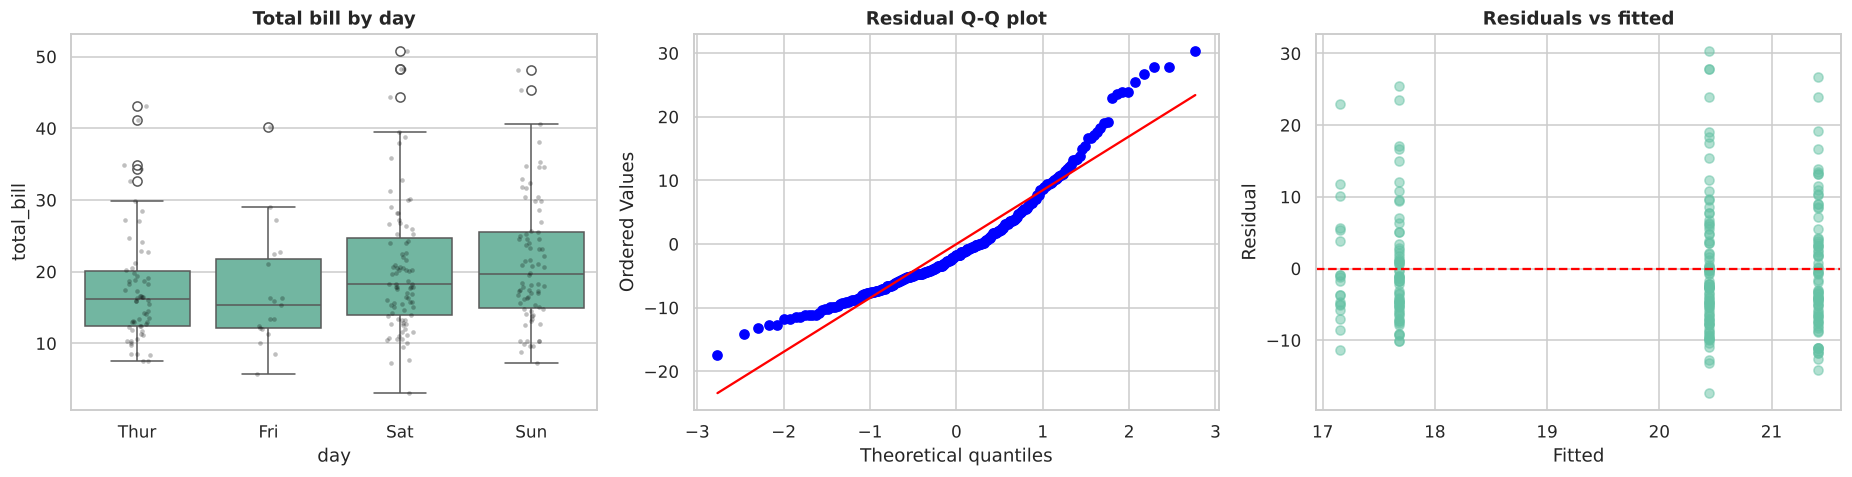

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x='day', y='total_bill', order=days, ax=ax[0]); sns.stripplot(data=df, x='day', y='total_bill', order=days, color='k', alpha=.25, size=3, ax=ax[0])
ax[0].set_title('Total bill by day')
stats.probplot(m1.resid, dist='norm', plot=ax[1]); ax[1].set_title('Residual Q-Q plot')
ax[2].scatter(m1.fittedvalues, m1.resid, alpha=.5); ax[2].axhline(0, color='r', ls='--')
ax[2].set_xlabel('Fitted'); ax[2].set_ylabel('Residual'); ax[2].set_title('Residuals vs fitted')
plt.tight_layout(); plt.show()

### Tukey HSD post-hoc test

If the omnibus ANOVA is significant, Tukey's Honestly Significant Difference test compares **every pair of days** while controlling the family-wise error rate at 5%.
- **H₀ (per pair):** the two days have equal mean bills; **H₁:** they differ.

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   3.2898 0.4541 -2.4799  9.0595  False
   Fri    Sun   4.2584 0.2371 -1.5856 10.1025  False
   Fri   Thur   0.5312 0.9957 -5.4434  6.5057  False
   Sat    Sun   0.9686 0.8968 -2.6088   4.546  False
   Sat   Thur  -2.7586 0.2374 -6.5455  1.0282  False
   Sun   Thur  -3.7273 0.0668 -7.6264  0.1719  False
----------------------------------------------------


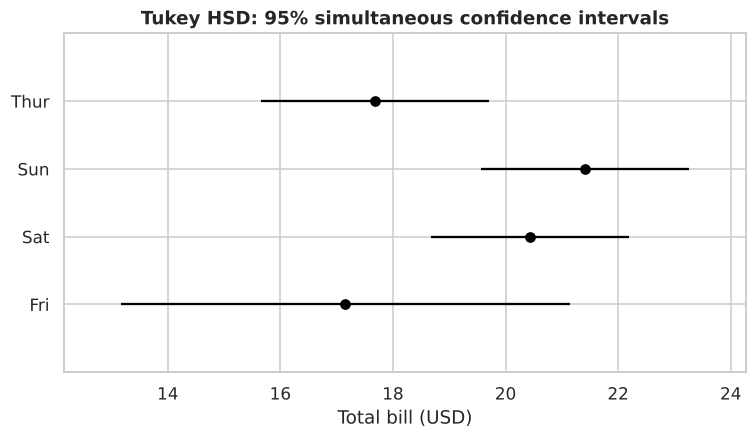

In [13]:
tuk = pairwise_tukeyhsd(df['total_bill'], df['day'], alpha=ALPHA)
print(tuk.summary())
tuk_df = pd.DataFrame(tuk.summary().data[1:], columns=tuk.summary().data[0])
tuk.plot_simultaneous(figsize=(8, 4)); plt.title('Tukey HSD: 95% simultaneous confidence intervals'); plt.xlabel('Total bill (USD)'); plt.show()

In [14]:
# 95% CI for each day's mean (t-based)
ci_tbl = df.groupby('day', observed=True)['total_bill'].agg(['count','mean','sem']).loc[days]
ci_tbl['CI low']  = ci_tbl['mean'] - stats.t.ppf(.975, ci_tbl['count']-1)*ci_tbl['sem']
ci_tbl['CI high'] = ci_tbl['mean'] + stats.t.ppf(.975, ci_tbl['count']-1)*ci_tbl['sem']
display(ci_tbl.round(2))

,count,mean,sem,CI low,CI high
day,,,,,
Thur,62,17.68,1.00,15.68,19.69
Fri,19,17.15,1.90,13.15,21.15
Sat,87,20.44,1.02,18.42,22.46
Sun,76,21.41,1.01,19.39,23.43


### Robustness: ANOVA on the log-transformed bill

Residuals of the raw bill are not normal (see above), but the **log bill is** (Shapiro-Wilk p = 0.16 earlier). Repeating both ANOVAs on `log(total_bill)` checks that the conclusions do not depend on the normality violation.

In [15]:
df['log_bill'] = np.log(df['total_bill'])
ml1 = smf.ols('log_bill ~ C(day)', data=df).fit()
ml2 = smf.ols('log_bill ~ C(day) * C(smoker)', data=df).fit()
print('Residual normality, one-way (log): W=%.4f, p=%.4f' % stats.shapiro(ml1.resid))
print('Residual normality, two-way (log): W=%.4f, p=%.4f' % stats.shapiro(ml2.resid))
print('\nOne-way ANOVA on log bill'); display(sm.stats.anova_lm(ml1, typ=2).round(4))
print('Two-way ANOVA on log bill'); display(sm.stats.anova_lm(ml2, typ=2).round(4))
print(pairwise_tukeyhsd(df['log_bill'], df['day'], alpha=ALPHA).summary())

Residual normality, one-way (log): W=0.9897, p=0.0819
Residual normality, two-way (log): W=0.9885, p=0.0490

One-way ANOVA on log bill


,sum_sq,df,F,PR(>F)
C(day),1.7707,3.0,3.1456,0.0258
Residual,45.0340,240.0,NaN,NaN


Two-way ANOVA on log bill


,sum_sq,df,F,PR(>F)
C(day),1.9376,3.0,3.4328,0.0177
C(smoker),0.3057,1.0,1.6249,0.2037
C(day):C(smoker),0.3250,3.0,0.5758,0.6315
Residual,44.4033,236.0,NaN,NaN


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   0.1765 0.3753 -0.1073  0.4603  False
   Fri    Sun   0.2401 0.1373 -0.0474  0.5275  False
   Fri   Thur   0.0464 0.9769 -0.2475  0.3403  False
   Sat    Sun   0.0635 0.7864 -0.1124  0.2395  False
   Sat   Thur  -0.1301 0.2723 -0.3164  0.0561  False
   Sun   Thur  -0.1937 0.0468 -0.3855 -0.0019   True
----------------------------------------------------


## 5. Two-Way ANOVA

**Research question:** how do `day` and `smoker` status jointly influence the bill? Two-way ANOVA tests three effects at once:

| Effect | H₀ | H₁ |
|---|---|---|
| Main effect of **day** | All day means equal | Some day mean differs |
| Main effect of **smoker** | Smoker and non-smoker means equal | Means differ |
| **Day × Smoker interaction** | The effect of day is the same for smokers and non-smokers | The day pattern differs by smoker status |

The design is unbalanced (unequal cell sizes), so we use **Type II sums of squares**.

In [16]:
display(pd.crosstab(df['smoker'], df['day'])[days])
m2 = smf.ols('total_bill ~ C(day) * C(smoker)', data=df).fit()
anova2 = sm.stats.anova_lm(m2, typ=2)
anova2['eta_sq_partial'] = anova2['sum_sq'] / (anova2['sum_sq'] + anova2.loc['Residual','sum_sq'])
display(anova2.round(4))
for term, name in [('C(day)','Day'), ('C(smoker)','Smoker'), ('C(day):C(smoker)','Day x Smoker')]:
    RESULTS.append({'Test': f'Two-way ANOVA: {name}', 'Statistic': anova2.loc[term,'F'], 'p-value': anova2.loc[term,'PR(>F)'],
                    'Decision': 'Reject H0' if anova2.loc[term,'PR(>F)']<ALPHA else 'Fail to reject H0'})
print('Residual normality (Shapiro-Wilk): W=%.4f, p=%.4f' % stats.shapiro(m2.resid))
print('Levene across the 8 cells        : W=%.4f, p=%.4f' % stats.levene(*[g['total_bill'].values for _, g in df.groupby(['day','smoker'], observed=True)]))

day,Thur,Fri,Sat,Sun
smoker,,,,
Yes,17,15,42,19
No,45,4,45,57


,sum_sq,df,F,PR(>F),eta_sq_partial
C(day),725.4128,3.0,3.1166,0.0269,0.0381
C(smoker),222.9853,1.0,2.8740,0.0913,0.0120
C(day):C(smoker),81.1234,3.0,0.3485,0.7902,0.0044
Residual,18310.4140,236.0,NaN,NaN,0.5000


Residual normality (Shapiro-Wilk): W=0.9253, p=0.0000
Levene across the 8 cells        : W=1.0079, p=0.4263


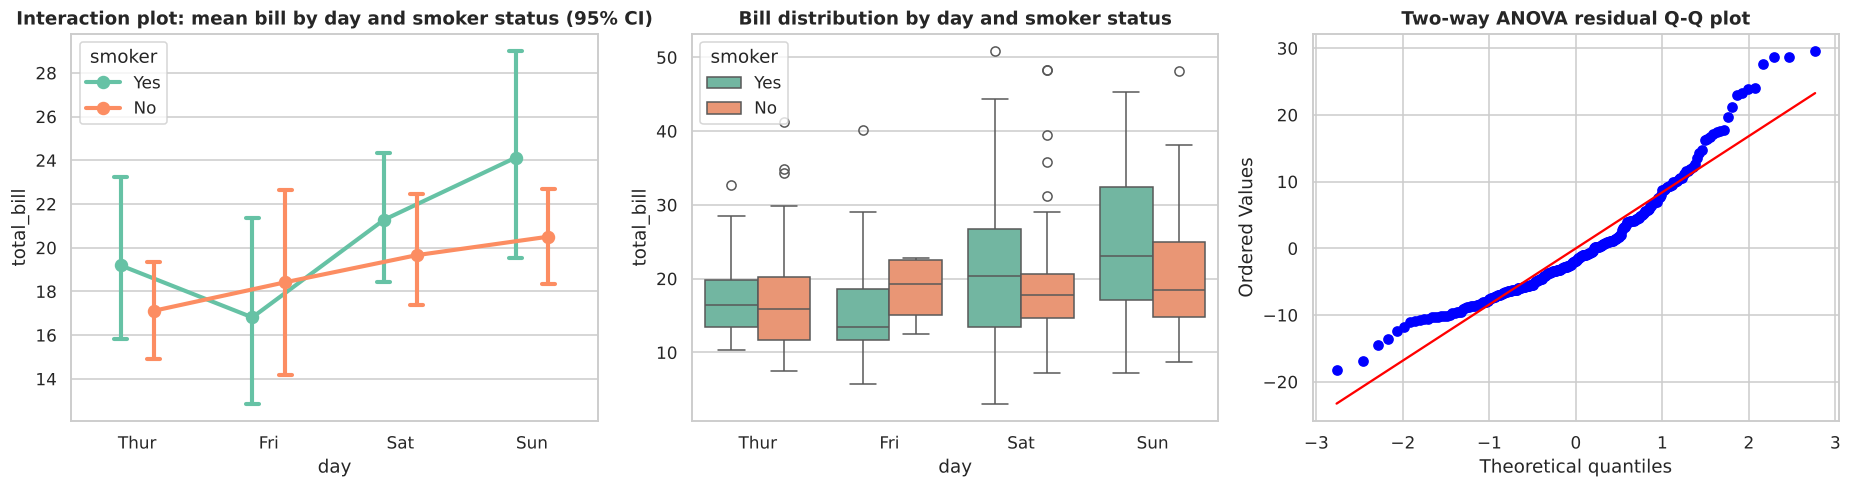

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.pointplot(data=df, x='day', y='total_bill', hue='smoker', order=days, dodge=.25, errorbar=('ci',95), capsize=.1, ax=ax[0])
ax[0].set_title('Interaction plot: mean bill by day and smoker status (95% CI)')
sns.boxplot(data=df, x='day', y='total_bill', hue='smoker', order=days, ax=ax[1]); ax[1].set_title('Bill distribution by day and smoker status')
stats.probplot(m2.resid, dist='norm', plot=ax[2]); ax[2].set_title('Two-way ANOVA residual Q-Q plot')
plt.tight_layout(); plt.show()

### Tukey HSD for the Two-Way design

We run Tukey on the **day** factor (the factor with more than two levels) and on every **day × smoker cell combination** to locate where any differences lie.

In [18]:
print('--- Tukey HSD: day (main effect) ---')
print(pairwise_tukeyhsd(df['total_bill'], df['day'], alpha=ALPHA).summary())
df['cell'] = df['day'].astype(str) + '-' + df['smoker'].astype(str)
tk_cell = pairwise_tukeyhsd(df['total_bill'], df['cell'], alpha=ALPHA)
cell_df = pd.DataFrame(tk_cell.summary().data[1:], columns=tk_cell.summary().data[0])
print('\n--- Tukey HSD: day x smoker cells, significant pairs only ---')
display(cell_df[cell_df['reject']==True].reset_index(drop=True))

--- Tukey HSD: day (main effect) ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   3.2898 0.4541 -2.4799  9.0595  False
   Fri    Sun   4.2584 0.2371 -1.5856 10.1025  False
   Fri   Thur   0.5312 0.9957 -5.4434  6.5057  False
   Sat    Sun   0.9686 0.8968 -2.6088   4.546  False
   Sat   Thur  -2.7586 0.2374 -6.5455  1.0282  False
   Sun   Thur  -3.7273 0.0668 -7.6264  0.1719  False
----------------------------------------------------



--- Tukey HSD: day x smoker cells, significant pairs only ---


,group1,group2,meandiff,p-adj,lower,upper,reject


## 6. Multiple-Comparison and Robustness Notes

We ran several tests, so the chance of at least one false positive rises. We apply a **Holm correction** to the family of primary p-values to confirm that the conclusions hold.

In [19]:
from statsmodels.stats.multitest import multipletests
res = pd.DataFrame(RESULTS)
rej, p_adj, _, _ = multipletests(res['p-value'], alpha=ALPHA, method='holm')
res['Holm-adj p'] = p_adj
res['Significant after Holm?'] = np.where(rej, 'Yes', 'No')
summary = res.copy()
summary['Statistic'] = summary['Statistic'].round(3)
summary['p-value'] = summary['p-value'].map(lambda v: f'{v:.4g}')
summary['Holm-adj p'] = summary['Holm-adj p'].map(lambda v: f'{v:.4g}')
summary

,Test,Statistic,p-value,Decision,Holm-adj p,Significant after Holm?
0,"Welch t-test: total_bill, Smoker vs Non-smoker",1.284,0.2008,Fail to reject H0,1,No
1,"Mann-Whitney U: total_bill, Smoker vs Non-smoker",7531.500,0.3413,Fail to reject H0,1,No
2,"Welch t-test: tip_pct, Smoker vs Non-smoker",0.411,0.6817,Fail to reject H0,1,No
3,"Mann-Whitney U: tip_pct, Smoker vs Non-smoker",6709.500,0.5607,Fail to reject H0,1,No
4,"Welch t-test: total_bill, Dinner vs Lunch",3.123,0.002167,Reject H0,0.02167,Yes
5,"Mann-Whitney U: total_bill, Dinner vs Lunch",7587.500,0.001183,Reject H0,0.01302,Yes
6,One-way ANOVA: total_bill ~ day,2.767,0.04245,Reject H0,0.2972,No
7,Kruskal-Wallis: total_bill ~ day,10.403,0.01543,Reject H0,0.1389,No
8,Two-way ANOVA: Day,3.117,0.02689,Reject H0,0.2151,No
9,Two-way ANOVA: Smoker,2.874,0.09134,Fail to reject H0,0.548,No


## 7. Findings and Conclusions

### 7.1 Summary of results

| # | Question | Test(s) | Result (α = 0.05) | Practical size |
|---|---|---|---|---|
| 1 | Normality | Shapiro-Wilk, KS, Lilliefors | Bills are **right-skewed and non-normal** in every group (skew 0.8 to 1.3; SW p < 0.05 everywhere). Tip % is non-normal for smokers (skew 3.2) but normal for non-smokers (SW p = 0.31). A **log transform fixes the bill** (SW p = 0.16). | n/a |
| 2 | Bill: Smoker vs Non-smoker | Welch t, Mann-Whitney U | **Not significant** (t p = 0.20, U p = 0.34). Smokers' mean bill is $1.57 higher, but the 95% CI [-$0.84, $3.98] includes 0. | Cohen's d = 0.18 (small) |
| 3 | Tip %: Smoker vs Non-smoker | Welch t, Mann-Whitney U | **Not significant** (p = 0.68 and 0.56). Difference 0.39 points, 95% CI [-1.48, 2.25]. | d = 0.06 (negligible) |
| 4 | Bill: Dinner vs Lunch | Welch t, Mann-Whitney U | **Significant** (p = 0.0022 and 0.0012). Dinner is $3.63 higher, 95% CI [$1.33, $5.93]. | d = 0.41 (small to medium) |
| 5 | Bill across 4 days | One-way ANOVA, Kruskal-Wallis | **Significant** (F = 2.77, p = 0.043; H p = 0.015), but the effect is small (η² = 0.033). Raw-scale Tukey HSD finds **no individual pair** significant (Sun vs Thu is closest, p = 0.067). On the **log scale**, where assumptions hold, Tukey finds **Sunday > Thursday** (p = 0.047). | η² = 0.03 (small) |
| 6 | Bill by day × smoker | Two-way ANOVA (Type II) | **Day is significant** (F = 3.12, p = 0.027, partial η² = 0.038). Smoker status (p = 0.091) and the **day × smoker interaction (p = 0.79)** are not significant. The log-scale model agrees (day p = 0.018). Tukey on the 8 cells finds no significant pair. | partial η² ≤ 0.038 |

### 7.2 Interpretation

1. **Normality matters here.** Bills are clearly skewed, so the Mann-Whitney and Kruskal-Wallis tests are the safest primary tests for the raw bill. The parametric and non-parametric tests **agreed** on every two-sample decision, and the bootstrap confidence intervals agreed too, so the conclusions are robust.
2. **Dinner bills are larger than lunch bills**, and this is the strongest finding. It is the only result that stays significant after the Holm correction across all 11 tests (adjusted p = 0.022 and 0.013).
3. **Smoking status has no detectable link to bill size or tip percentage.** Both confidence intervals include zero and the effects are small to negligible. The unequal tip variances (Levene p = 0.0002) are driven by a few extreme tippers among smokers, which is why the Welch test and the rank test were used.
4. **Day of week has a modest effect on the bill.** It appears in both the one-way and the two-way ANOVA, but no raw-scale Tukey pair clears the conservative threshold. This shows that an omnibus ANOVA can be significant without any single pair being significant. Weekend days (Sat, Sun) trend higher than Thursday and Friday, with Sunday vs Thursday the clearest contrast on the log scale. After the Holm correction the day effect is no longer significant, so treat it as suggestive.
5. **No interaction between day and smoker status.** The day-of-week pattern is similar for smokers and non-smokers, so the two factors can be interpreted separately.
6. **Model assumptions.** The raw-bill ANOVA residuals are not normal, but the log-scale models give the same conclusions (the two-way log residuals are borderline, p = 0.049), and Levene's test supports equal variances across the day × smoker cells (p = 0.43).

### 7.3 Business recommendations

- **Staffing and forecasting:** plan for higher revenue per party at dinner and (modestly) on Sundays.
- **Tipping strategy:** there is no evidence that smoking-section placement changes the bill or the tip percentage, so it need not be a factor in table assignment.
- **Follow-up:** collect data from more days and venues, and model `size` (party size), which likely explains most of the bill differences found here.

> **Note on the Holm correction.** It was applied across all 11 tests, including parametric and non-parametric versions of the same question, so it is deliberately conservative. Reporting both the raw and the adjusted p-values lets the reader judge the strength of each finding.

## 8. Limitations

- The data come from one waiter at one restaurant, so results may not generalise to other venues or countries.
- Observations may not be fully independent (the same tables or regulars may repeat).
- The design is unbalanced, and some day × smoker cells are small, which reduces power for interaction tests.
- This is observational data: significant differences describe association, not causation.

## 9. Tools

Python 3, pandas, NumPy, SciPy (`shapiro`, `kstest`, `ttest_ind`, `mannwhitneyu`, `f_oneway`, `kruskal`), statsmodels (OLS, ANOVA, Tukey HSD, Lilliefors, Holm), seaborn, matplotlib.